# H2O AutoML aplicado a la serie de radiación solar — Pronóstico a 24 horas y a 1 semana (versión mejorada para picos)

Versión para ejecutar directamente, celda por celda, desde Jupyter Notebook o JupyterLab. No requiere SLURM.

## ¿Qué cambió respecto de la versión anterior?

En la versión anterior el modelo predecía directamente la radiación en W/m². Al pronosticar a 24 horas, el modelo no sabe si mañana habrá nubes, y con pérdida cuadrática (RMSE) la mejor apuesta es un **promedio** entre el escenario despejado y el nublado. Por eso los picos quedaban achatados (≈ 400–450 cuando el real era ≈ 550–600) y, además, ~la mitad de las filas eran noches con radiación 0 que el modelo aprendía "gratis".

Esta versión introduce cinco cambios:

1. **Envolvente de cielo despejado.** Para cada instante objetivo se estima cuánta radiación habría con cielo despejado, usando un cuantil alto (0,95) de la radiación observada **en el mismo horario** durante los 14 días previos. Sólo usa información conocida en `t` (sin fuga de datos) y sigue sola el cambio estacional.
2. **Nuevo objetivo: índice de claridad** `kt = radiación / cielo_despejado` (entre 0 y 1,3). El modelo ya no tiene que aprender la forma de la campana ni su altura: sólo aprende *qué fracción* del cielo despejado llegará. Luego se vuelve a W/m² multiplicando por la envolvente, así la altura del pico queda anclada al valor físico del día.
3. **Sólo se entrena con horas diurnas.** La noche se pronostica como 0 directamente.
4. **Pesos por radiación** (`weights_column`). Cada fila pesa según el cuadrado de la envolvente, de modo que los errores del mediodía (los picos) cuentan más, igual que en el RMSE en W/m².
5. **Variables nuevas que anticipan el cambio de tiempo**: tendencia de presión y humedad a 3 h y 24 h, amplitud térmica de las últimas 24 h, energía del último día relativa al cielo despejado, índices de claridad recientes y la radiación del mismo horario en días anteriores. Además se habilitan los **Stacked Ensembles** de H2O.

También se agregan **métricas específicas de picos** (error del máximo diario y error en el 10 % de valores más altos) y dos **modelos de referencia** (persistencia y climatología) para verificar que el modelo realmente aporta.

> **Límite importante:** sin un pronóstico meteorológico de nubosidad, ningún modelo puede saber con certeza si mañana estará nublado. Esta versión mejora la altura y la forma de los picos en días despejados, pero los días nublados imprevistos seguirán teniendo error. Ver la sección final para la mejora siguiente.

Los resultados se guardan en `resultados_h2o_radiacion_v2/` con la misma estructura de carpetas (`24h/`, `7d/`, cada una con `graficos/`, `metricas/` y `modelos/`), para poder comparar con la versión anterior.

## 1. Instalación de librerías
Ejecutar esta celda solamente si las librerías no están instaladas.

In [6]:
%pip install -q h2o pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 2. Carga de librerías

In [1]:
import os
import json
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import h2o
from h2o.automl import H2OAutoML
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 50)
plt.style.use('seaborn-v0_8-whitegrid')

## 3. Carga de la base de radiación

In [2]:
RUTA_DATOS = 'unificada.csv'  # Cambiar si el archivo está en otra carpeta
df = pd.read_csv(RUTA_DATOS, sep=';', low_memory=False)
df.head()

,fecha,temperatura,humedad,presion,radiacion,precipitacion,precipitacion_acum_diaria,veloc_de_viento_max_10m,veloc_de_viento_min_10m,veloc_de_viento_prom_10m,direccion_de_viento_a_10m,direccion_a_10m,veloc_de_viento_max_2m,veloc_de_viento_min_2m,veloc_de_viento_prom_2m,direccion_de_viento_a_2m,direccion_a_2m,evaporimetro,evaporacion_acum_diaria
0,18/8/2016 01:00,NaN,24.2,954.5,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1,18/8/2016 01:15,18.9,24.0,954.5,0.0,0.0,0.0,44.8,0.0,26.7,13.3,NaN,33.1,0.0,17.7,23.6,NaN,NaN,NaN
2,18/8/2016 01:30,19.0,23.6,954.5,0.0,0.0,0.0,46.6,0.0,27.5,14.2,NaN,30.4,0.0,17.7,23.6,NaN,NaN,NaN
3,18/8/2016 01:45,19.1,23.4,954.5,0.0,0.0,0.0,49.3,0.0,28.1,12.2,NaN,34.9,0.0,18.4,20.8,NaN,NaN,NaN
4,18/8/2016 02:00,19.0,23.4,954.5,0.0,0.0,0.0,42.1,0.0,26.1,15.2,NaN,29.5,0.0,17.3,23.2,NaN,NaN,NaN


## 4. Análisis exploratorio general

In [5]:
print('Dimensión:', df.shape)
df.info()

Dimensión: (336764, 18)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 336764 entries, 2016-08-18 01:00:00 to 2026-08-12 22:15:00
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   temperatura                336639 non-null  float64
 1   humedad                    336663 non-null  float64
 2   presion                    335003 non-null  float64
 3   radiacion                  336464 non-null  float64
 4   precipitacion              336725 non-null  float64
 5   precipitacion_acum_diaria  335908 non-null  float64
 6   veloc_de_viento_max_10m    336764 non-null  float64
 7   veloc_de_viento_min_10m    336764 non-null  float64
 8   veloc_de_viento_prom_10m   336764 non-null  float64
 9   direccion_de_viento_a_10m  336607 non-null  float64
 10  direccion_a_10m            290843 non-null  object 
 11  veloc_de_viento_max_2m     336764 non-null  object 
 12  veloc_de_viento_min_2m     3

In [4]:
# Conversión de fecha y columnas numéricas
df['fecha'] = pd.to_datetime(df['fecha'], dayfirst=True, errors='coerce')
variables = [
    'radiacion', 'temperatura', 'humedad', 'presion', 'precipitacion',
    'precipitacion_acum_diaria', 'veloc_de_viento_prom_10m',
    'veloc_de_viento_prom_2m'
]
variables = [c for c in variables if c in df.columns]
for c in variables:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.', regex=False), errors='coerce')

df = (df.dropna(subset=['fecha'])
        .sort_values('fecha')
        .drop_duplicates('fecha', keep='last')
        .set_index('fecha'))
df[variables].describe().T

,count,mean,std,min,25%,50%,75%,max
radiacion,336464.0,192.934876,278.726192,0.0,0.0,1.5,360.6,999.8
temperatura,336639.0,21.510030,7.905230,-38.3,16.1,22.0,27.3,44.8
humedad,336663.0,49.399627,20.569982,1.0,32.6,47.9,63.9,100.0
presion,335003.0,951.621044,12.233353,25.3,947.8,951.6,955.8,974.6
precipitacion,336725.0,0.013428,0.270754,0.0,0.0,0.0,0.0,90.7
precipitacion_acum_diaria,335908.0,0.708566,4.069848,0.0,0.0,0.0,0.0,90.7
veloc_de_viento_prom_10m,336764.0,11.559930,8.957427,0.0,4.0,9.9,18.3,61.4
veloc_de_viento_prom_2m,336764.0,7.335422,6.521024,0.0,1.0,6.1,12.1,44.3


In [6]:
calidad = pd.DataFrame({
    'tipo': df[variables].dtypes.astype(str),
    'faltantes': df[variables].isna().sum(),
    'porcentaje_faltante': df[variables].isna().mean().mul(100).round(2)
})
calidad

,tipo,faltantes,porcentaje_faltante
radiacion,float64,300,0.09
temperatura,float64,125,0.04
humedad,float64,101,0.03
presion,float64,1761,0.52
precipitacion,float64,39,0.01
precipitacion_acum_diaria,float64,856,0.25
veloc_de_viento_prom_10m,float64,0,0.00
veloc_de_viento_prom_2m,float64,0,0.00


## 5. Visualización de la radiación y las variables meteorológicas

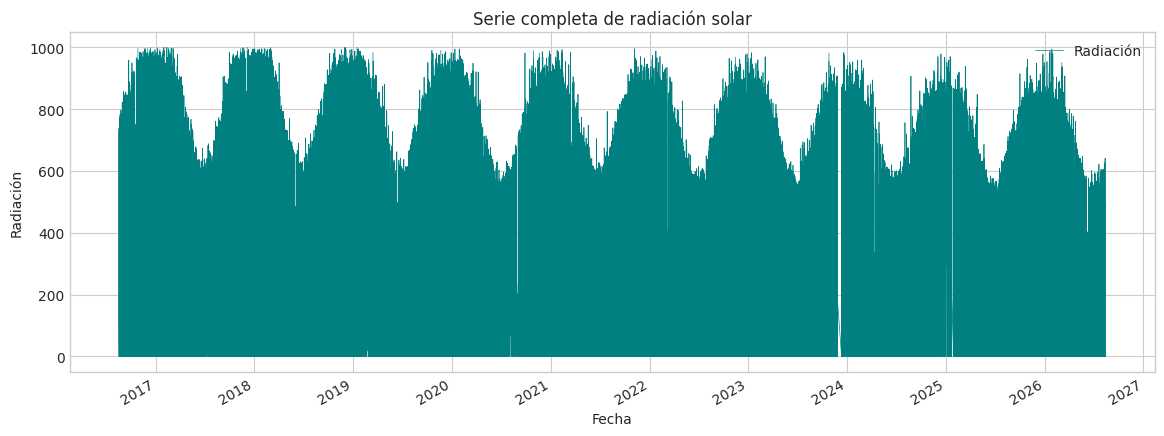

In [7]:
ax = df['radiacion'].plot(label='Radiación', color='teal', figsize=(14, 5), lw=0.5)
ax.set(title='Serie completa de radiación solar', xlabel='Fecha', ylabel='Radiación')
plt.legend();
plt.show()

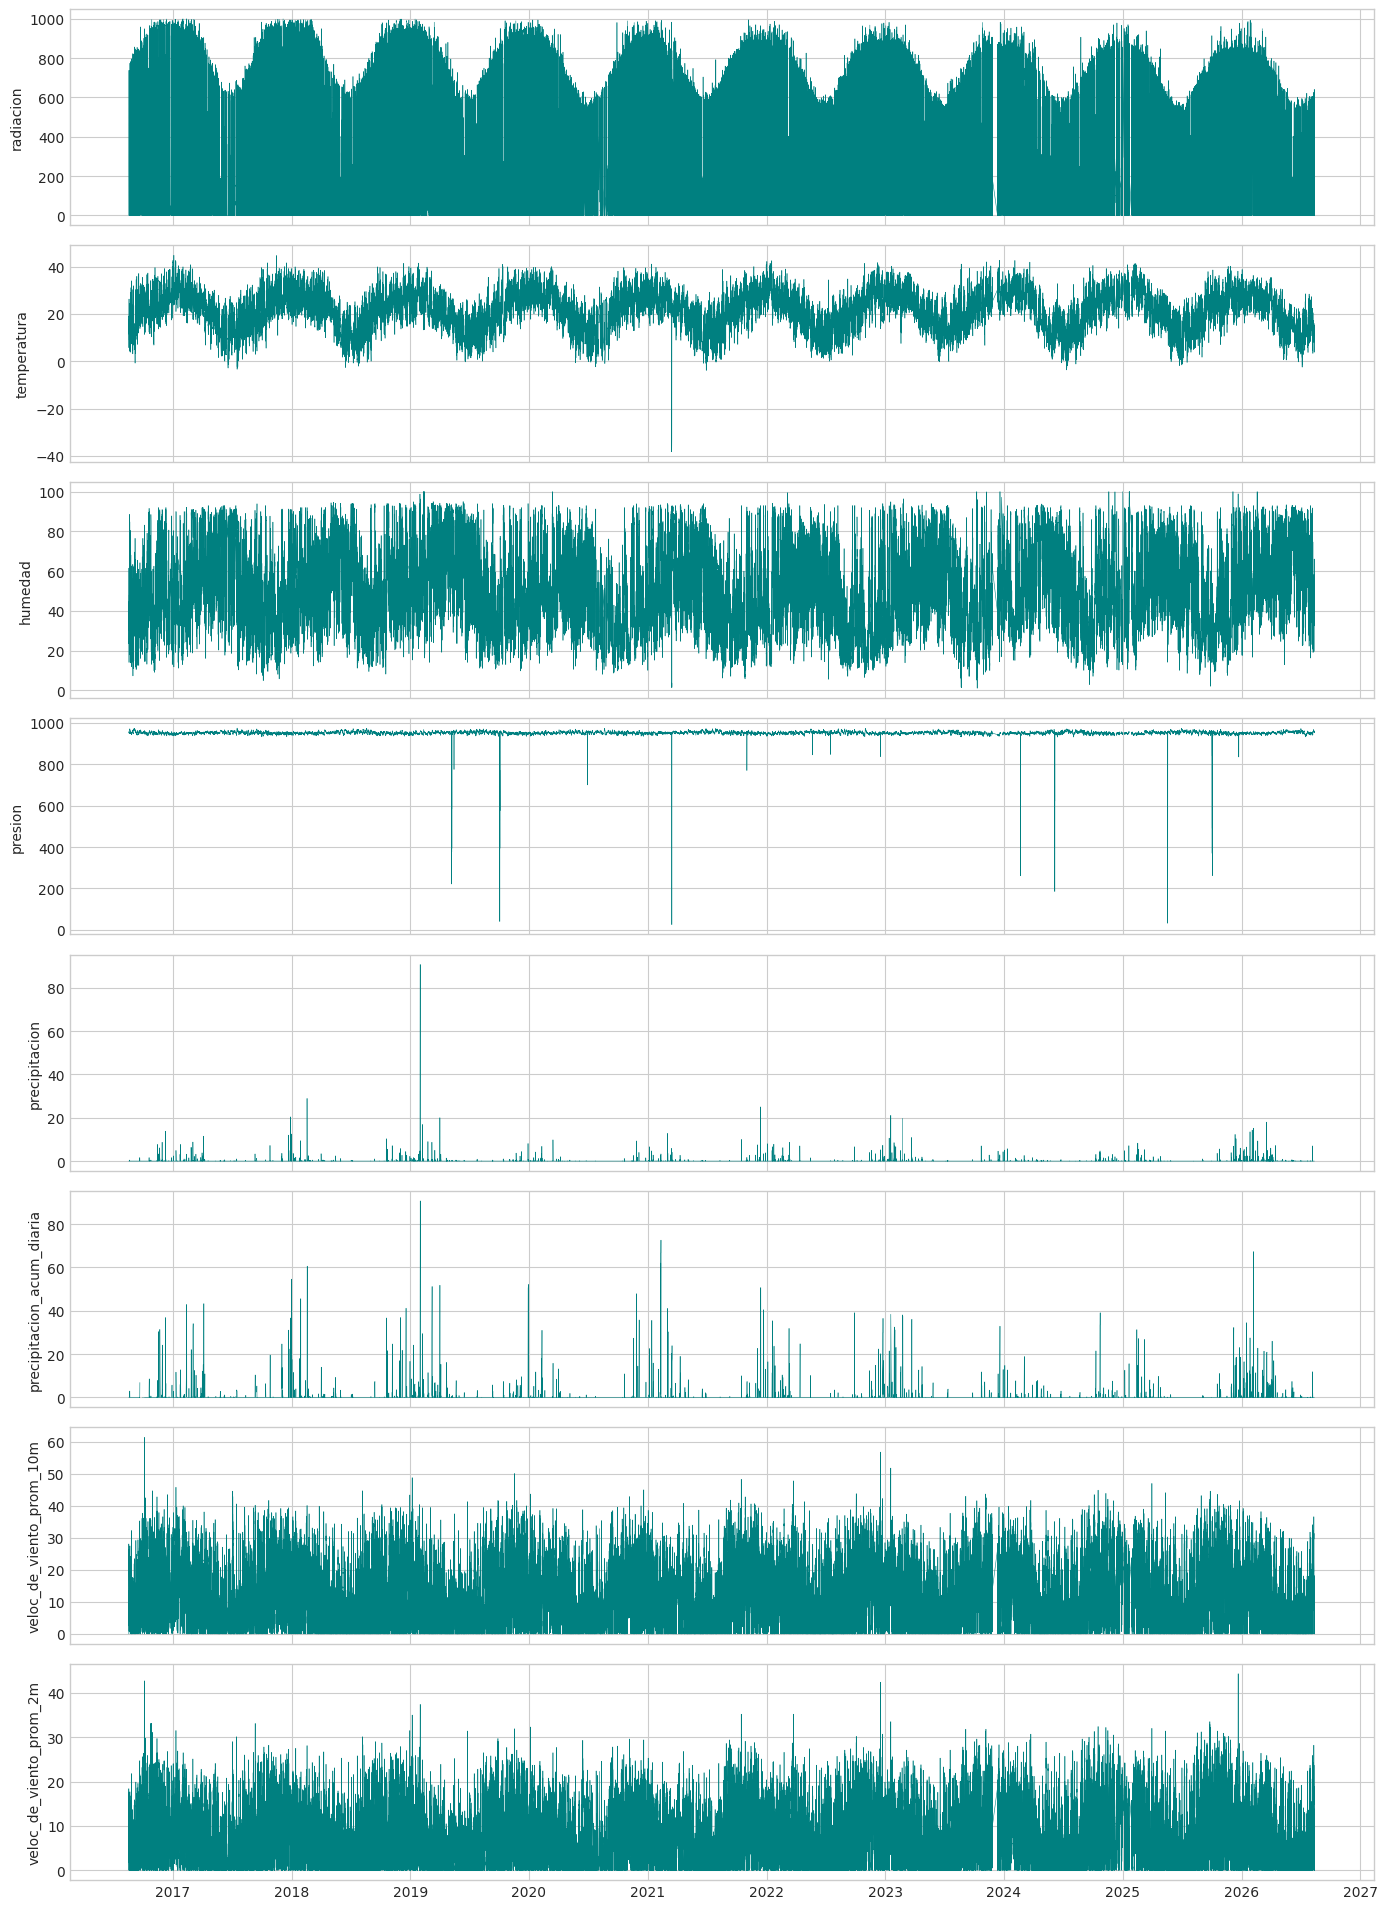

In [9]:
columnas_grafico = [c for c in variables if c in df.columns]
fig, axes = plt.subplots(len(columnas_grafico), 1, figsize=(14, 2.4*len(columnas_grafico)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), columnas_grafico):
    ax.plot(df.index, df[c], color='teal', lw=0.4)
    ax.set_ylabel(c)
plt.tight_layout();
plt.show()

## 6. Matriz de correlación

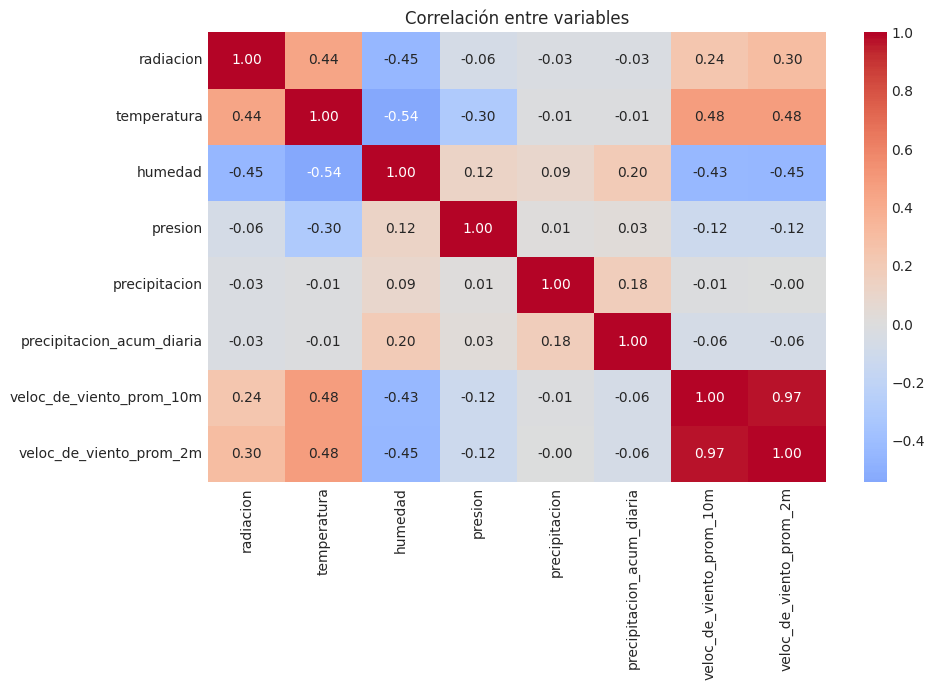

In [10]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[variables].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlación entre variables')
plt.tight_layout();
plt.show()

## 7. Regularización de la frecuencia
Se reconstruye la frecuencia exacta de 15 minutos para que los retardos y los horizontes de pronóstico representen siempre el mismo intervalo de tiempo real.

In [11]:
df_modelo = df[variables].copy()
indice_regular = pd.date_range(df_modelo.index.min(), df_modelo.index.max(), freq='15min')
df_modelo = df_modelo.reindex(indice_regular)
df_modelo.index.name = 'fecha'

exogenas = [c for c in variables if c != 'radiacion']
df_modelo[exogenas] = df_modelo[exogenas].interpolate(
    method='time', limit=4, limit_direction='both'
)
df_modelo.loc[df_modelo['radiacion'] < 0, 'radiacion'] = np.nan
print('Período:', df_modelo.index.min(), 'a', df_modelo.index.max())
print('Filas regulares:', len(df_modelo))

Período: 2016-08-18 01:00:00 a 2026-08-12 22:15:00
Filas regulares: 350102


## 8. Envolvente de cielo despejado e índice de claridad

La envolvente para el instante objetivo `t + h` se calcula con la radiación observada en el mismo horario de días anteriores: `radiación(t + h − 96·k)` para `k` desde el primer día ya observado en `t` y durante `DIAS_ENVOLVENTE` días. Se toma el cuantil 0,95 (en lugar del máximo) para no dejarse arrastrar por picos puntuales de "realce por nubes".

- Horizonte 24 h (h = 96): usa los días `t`, `t−1 día`, …, `t−13 días`, siempre en el horario objetivo.
- Horizonte 1 semana (h = 672): usa desde `t` hacia atrás, en el mismo horario, con 14 días de ventana.

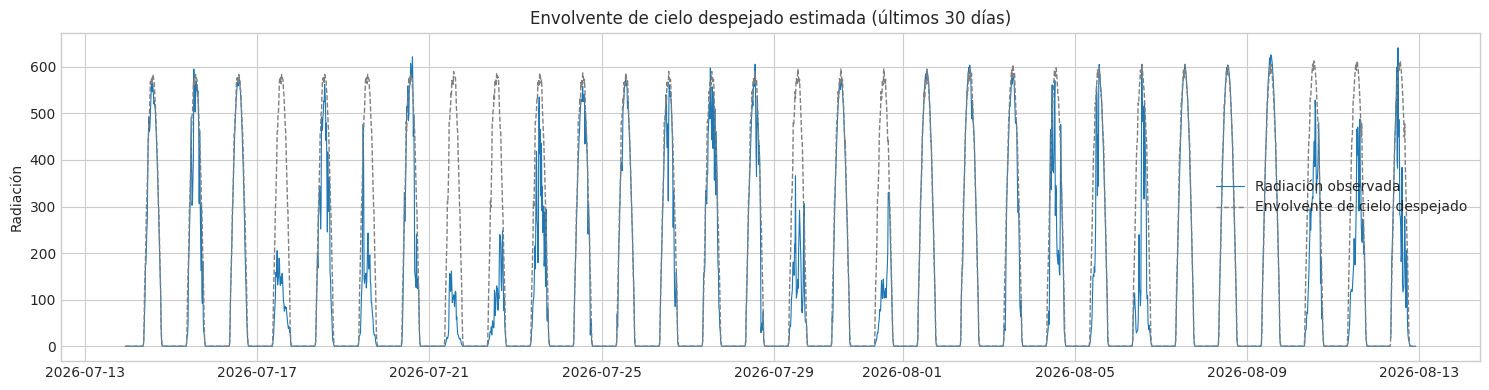

In [12]:
PASOS_DIA = 96
DIAS_ENVOLVENTE = 14       # días previos usados para estimar el cielo despejado
CUANTIL_ENVOLVENTE = 0.95  # cuantil alto: más robusto que el máximo ante picos por nubes
UMBRAL_DIURNO = 20         # W/m²: si el cielo despejado esperado es menor, se considera noche y se pronostica 0
KT_MAX = 1.3               # tope del índice de claridad (permite el realce por nubes)


def envolvente_cielo_despejado(rad, horizonte_pasos):
    """Radiación de cielo despejado estimada para el instante t + horizonte_pasos,
    usando sólo valores de radiación conocidos en t (mismo horario, días previos)."""
    k0 = max(1, math.ceil(horizonte_pasos / PASOS_DIA))
    desfases = [PASOS_DIA * k - horizonte_pasos for k in range(k0, k0 + DIAS_ENVOLVENTE)]
    matriz = np.column_stack([rad.shift(d).to_numpy() for d in desfases])
    minimo_dias = DIAS_ENVOLVENTE // 2
    validos = np.sum(~np.isnan(matriz), axis=1)
    with np.errstate(all='ignore'):
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=RuntimeWarning)
            env = np.nanquantile(matriz, CUANTIL_ENVOLVENTE, axis=1)
    env[validos < minimo_dias] = np.nan
    return pd.Series(env, index=rad.index)


# Vista rápida de la envolvente sobre el último mes de datos
_env = envolvente_cielo_despejado(df_modelo['radiacion'], 0)
_ultimo_mes = df_modelo.index >= df_modelo.index.max() - pd.Timedelta(days=30)
plt.figure(figsize=(15, 4))
plt.plot(df_modelo.index[_ultimo_mes], df_modelo['radiacion'][_ultimo_mes], lw=0.8, label='Radiación observada')
plt.plot(df_modelo.index[_ultimo_mes], _env[_ultimo_mes], '--', color='gray', lw=1, label='Envolvente de cielo despejado')
plt.title('Envolvente de cielo despejado estimada (últimos 30 días)')
plt.ylabel('Radiación'); plt.legend(); plt.tight_layout(); plt.show()

## 9. Conversión de la serie temporal en aprendizaje supervisado (parametrizada por horizonte)

Todas las variables usan información disponible hasta el instante `t`. El objetivo del modelo pasa a ser `kt_objetivo` (índice de claridad en `t + h`); la radiación objetivo en W/m² se conserva sólo para evaluar.

In [13]:
def preparar_serie_supervisada(datos, horizonte_pasos, exogenas):
    rad = datos['radiacion']
    h = horizonte_pasos
    s = pd.DataFrame(index=datos.index)

    # --- Envolventes de cielo despejado (objetivo y actual) ---
    s['cielo_desp_objetivo'] = envolvente_cielo_despejado(rad, h)
    cielo_t = envolvente_cielo_despejado(rad, 0)
    s['cielo_desp_t'] = cielo_t
    kt = (rad / cielo_t.where(cielo_t > UMBRAL_DIURNO)).clip(0, KT_MAX)

    # --- Radiación actual, retardos y estadísticos móviles ---
    s['radiacion_t'] = rad
    for lag in [1, 4, 96, 192, 672]:
        s[f'radiacion_lag_{lag}'] = rad.shift(lag)
    for ventana in [4, 12, 96]:
        minimo = max(2, ventana // 2)
        s[f'radiacion_media_{ventana}'] = rad.rolling(ventana, min_periods=minimo).mean()
        s[f'radiacion_std_{ventana}'] = rad.rolling(ventana, min_periods=minimo).std()
    s['radiacion_max_24h'] = rad.rolling(96, min_periods=48).max()

    # --- Radiación en el MISMO HORARIO que el objetivo, en los días previos disponibles ---
    k0 = max(1, math.ceil(h / PASOS_DIA))
    for j in range(3):
        s[f'rad_mismo_horario_d{j + 1}'] = rad.shift(PASOS_DIA * (k0 + j) - h)
    s['rad_mismo_horario_media_7d'] = pd.concat(
        [rad.shift(PASOS_DIA * (k0 + j) - h) for j in range(7)], axis=1).mean(axis=1)

    # --- Índice de claridad reciente: ¿qué tan despejado viene estando? ---
    s['kt_t'] = kt
    for ventana in [4, 12, 96, 288]:
        s[f'kt_media_{ventana}'] = kt.rolling(ventana, min_periods=1).mean()
    s['kt_std_96'] = kt.rolling(96, min_periods=8).std()
    s['energia_24h_relativa'] = (rad.rolling(96, min_periods=48).sum()
                                 / cielo_t.rolling(96, min_periods=48).sum())

    # --- Variables meteorológicas y sus tendencias (anticipan cambios de tiempo) ---
    for c in exogenas:
        s[f'{c}_t'] = datos[c]
        s[f'{c}_lag_1'] = datos[c].shift(1)
    for c in ['presion', 'humedad', 'temperatura']:
        if c in exogenas:
            s[f'{c}_dif_3h'] = datos[c].diff(12)
            s[f'{c}_dif_24h'] = datos[c].diff(96)
    if 'temperatura' in exogenas:
        s['amplitud_termica_24h'] = (datos['temperatura'].rolling(96, min_periods=48).max()
                                     - datos['temperatura'].rolling(96, min_periods=48).min())
    if 'humedad' in exogenas:
        s['humedad_media_24h'] = datos['humedad'].rolling(96, min_periods=48).mean()
    if 'precipitacion' in exogenas:
        s['precipitacion_24h'] = datos['precipitacion'].rolling(96, min_periods=48).sum()

    # --- Calendario del instante futuro que se desea pronosticar ---
    fecha_futura = s.index + pd.Timedelta(minutes=15 * h)
    minutos = fecha_futura.hour * 60 + fecha_futura.minute
    s['hora_sin'] = np.sin(2 * np.pi * minutos / 1440)
    s['hora_cos'] = np.cos(2 * np.pi * minutos / 1440)
    s['dia_anio_sin'] = np.sin(2 * np.pi * fecha_futura.dayofyear / 365.25)
    s['dia_anio_cos'] = np.cos(2 * np.pi * fecha_futura.dayofyear / 365.25)
    s['mes'] = fecha_futura.month

    # --- Objetivos ---
    s['radiacion_objetivo'] = rad.shift(-h)
    s['kt_objetivo'] = (s['radiacion_objetivo'] / s['cielo_desp_objetivo']).clip(0, KT_MAX)

    s = s.replace([np.inf, -np.inf], np.nan)
    # Los predictores pueden tener faltantes (H2O los maneja); sólo se exige objetivo y envolvente.
    s = s.dropna(subset=['radiacion_objetivo', 'cielo_desp_objetivo'])
    return s


COLUMNAS_NO_PREDICTORAS = ['radiacion_objetivo', 'kt_objetivo', 'peso']


def calcular_metricas(real, predicho):
    real = np.asarray(real, dtype=float)
    predicho = np.asarray(predicho, dtype=float)
    mascara = np.abs(real) > 1e-8
    return {
        'MAE': mean_absolute_error(real, predicho),
        'RMSE': np.sqrt(mean_squared_error(real, predicho)),
        'R2': r2_score(real, predicho),
        'MAPE_sin_ceros_pct': np.mean(np.abs((real[mascara] - predicho[mascara]) / real[mascara])) * 100
    }


def metricas_picos(fechas, real, predicho):
    """Métricas centradas en los picos: máximo diario y 10 % de valores más altos."""
    d = pd.DataFrame({'real': real, 'pred': predicho}, index=pd.DatetimeIndex(fechas))
    diario = d.groupby(d.index.date).max()
    diario = diario[diario['real'] > 100]  # descarta días casi sin datos
    umbral_alto = np.quantile(d.loc[d['real'] > UMBRAL_DIURNO, 'real'], 0.90)
    altos = d[d['real'] >= umbral_alto]
    return {
        'MAE_max_diario': mean_absolute_error(diario['real'], diario['pred']),
        'sesgo_max_diario': float((diario['pred'] - diario['real']).mean()),
        'MAE_top10pct': mean_absolute_error(altos['real'], altos['pred']),
        'sesgo_top10pct': float((altos['pred'] - altos['real']).mean()),
    }

## 10. Carpetas de resultados

Se usa una carpeta nueva (`_v2`) para no sobrescribir los resultados de la versión anterior.

In [14]:
BASE_RESULTADOS = 'resultados_h2o_radiacion_v2'

def crear_carpetas(nombre_horizonte):
    base = os.path.join(BASE_RESULTADOS, nombre_horizonte)
    carpetas = {
        'base': base,
        'graficos': os.path.join(base, 'graficos'),
        'metricas': os.path.join(base, 'metricas'),
        'modelos': os.path.join(base, 'modelos'),
    }
    for ruta in carpetas.values():
        os.makedirs(ruta, exist_ok=True)
    return carpetas

## 11. Inicialización de H2O

In [15]:
# Configuración para una computadora personal.
# Si dispone de poca memoria, cambiar MEMORIA_H2O a '4G'.
# Si dispone de 16 GB de RAM o más, puede conservar '8G'.
MEMORIA_H2O = '8G'
N_HILOS = 4
h2o.init(nthreads=N_HILOS, max_mem_size=MEMORIA_H2O)

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "17.0.18-internal" 2026-01-20; OpenJDK Runtime Environment (build 17.0.18-internal+0-adhoc.conda.src); OpenJDK 64-Bit Server VM (build 17.0.18-internal+0-adhoc.conda.src, mixed mode, sharing)
  Starting server from /home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpfkrgixy3
  JVM stdout: /tmp/tmpfkrgixy3/h2o_csosach_started_from_python.out
  JVM stderr: /tmp/tmpfkrgixy3/h2o_csosach_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,01 secs
H2O_cluster_timezone:,America/Argentina/Catamarca
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,1 month and 16 days
H2O_cluster_name:,H2O_from_python_csosach_rbhwty
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,8 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


## 12. Función de entrenamiento y evaluación por horizonte

Flujo por horizonte:

1. Preparación de variables y separación cronológica 70 / 15 / 15.
2. La validación se divide en dos mitades: la primera sirve para *early stopping* y para combinar los Stacked Ensembles (`blending_frame`); la segunda arma el ranking de modelos (`leaderboard_frame`), así el ranking no queda sesgado. La prueba (test) no se toca hasta el final.
3. Se entrena AutoML **sólo con filas diurnas**, prediciendo `kt_objetivo`, con pesos proporcionales al cuadrado de la envolvente.
4. La predicción se reconvierte a W/m²: `radiación = kt_predicho × cielo_despejado`; la noche vale 0.
5. Se compara contra dos referencias: **persistencia** (misma hora del último día observado) y **climatología** (cielo despejado × kt medio de entrenamiento).

In [16]:
TIEMPO_MAX_SEGUNDOS = 900  # 15 minutos por horizonte (ajustar según necesidad)
MAX_MODELOS = 20


def entrenar_evaluar_horizonte(horizonte_pasos, nombre_horizonte, etiqueta):
    print(f'=== Horizonte: {etiqueta} ({horizonte_pasos} pasos de 15 min) ===')
    carpetas = crear_carpetas(nombre_horizonte)

    # --- Preparación de datos ---
    df_h = preparar_serie_supervisada(df_modelo, horizonte_pasos, exogenas)
    df_h['peso'] = (df_h['cielo_desp_objetivo'] / df_h['cielo_desp_objetivo'].mean()) ** 2
    print(f'[{nombre_horizonte}] Filas utilizables:', len(df_h))

    # --- Separación cronológica ---
    n = len(df_h)
    corte_train, corte_val = int(n * 0.70), int(n * 0.85)
    df_train = df_h.iloc[:corte_train].copy()
    df_val = df_h.iloc[corte_train:corte_val].copy()
    df_test = df_h.iloc[corte_val:].copy()
    print(f'[{nombre_horizonte}] Entrenamiento:', df_train.shape, df_train.index.min(), df_train.index.max())
    print(f'[{nombre_horizonte}] Validación:', df_val.shape, df_val.index.min(), df_val.index.max())
    print(f'[{nombre_horizonte}] Prueba:', df_test.shape, df_test.index.min(), df_test.index.max())

    plt.figure(figsize=(14, 5))
    for parte, nombre in [(df_train, 'Train'), (df_val, 'Validación'), (df_test, 'Test')]:
        plt.plot(parte.index, parte['radiacion_objetivo'], label=nombre, lw=0.4)
    plt.ylabel(f'Radiación objetivo ({etiqueta})')
    plt.title(f'División cronológica de la serie - {etiqueta}')
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'division_train_val_test.png'), dpi=150)
    plt.show(); plt.close()

    # --- Sólo horas diurnas para entrenar ---
    def diurno(parte):
        return parte[(parte['cielo_desp_objetivo'] > UMBRAL_DIURNO) & parte['kt_objetivo'].notna()]
    tr_d, va_d = diurno(df_train), diurno(df_val)
    mitad = len(va_d) // 2
    va_a, va_b = va_d.iloc[:mitad], va_d.iloc[mitad:]
    print(f'[{nombre_horizonte}] Filas diurnas -> train: {len(tr_d)} | val (stop/blend): {len(va_a)} | val (ranking): {len(va_b)}')

    # Se fuerzan todas las columnas a numéricas: si una columna tiene muchos faltantes,
    # H2O podría adivinar otro tipo y fallar al comparar entrenamiento con validación.
    def a_h2o(parte):
        parte = parte.reset_index(drop=True).astype(float)
        return h2o.H2OFrame(parte, column_types={c: 'numeric' for c in parte.columns})

    hf_train, hf_val_a, hf_val_b = a_h2o(tr_d), a_h2o(va_a), a_h2o(va_b)

    X = [c for c in hf_train.columns if c not in COLUMNAS_NO_PREDICTORAS]
    y = 'kt_objetivo'
    print(f'[{nombre_horizonte}] Objetivo:', y, '| Cantidad de predictores:', len(X))

    # --- Entrenamiento con H2O AutoML ---
    aml = H2OAutoML(
        nfolds=0,
        max_runtime_secs=TIEMPO_MAX_SEGUNDOS,
        max_models=MAX_MODELOS,
        seed=42,
        sort_metric='RMSE',
        stopping_metric='RMSE',
        verbosity='info',
        exclude_algos=['DeepLearning'],   # ahora se permiten los Stacked Ensembles
        project_name=f'radiacion_kt_{nombre_horizonte}'
    )
    aml.train(x=X, y=y, training_frame=hf_train,
              validation_frame=hf_val_a, blending_frame=hf_val_a,
              leaderboard_frame=hf_val_b, weights_column='peso')

    leaderboard = aml.leaderboard.as_data_frame()
    leaderboard.to_csv(os.path.join(carpetas['metricas'], 'leaderboard.csv'), index=False)
    display(leaderboard.head(10))
    leader_model = aml.leader
    print(f'[{nombre_horizonte}] Modelo ganador:', leader_model.model_id)

    # --- Predicción sobre test (todas las filas, incluidas las nocturnas) ---
    kt_pred = leader_model.predict(a_h2o(df_test)).as_data_frame()['predict'].to_numpy()
    kt_pred = np.clip(kt_pred, 0, KT_MAX)
    cielo = df_test['cielo_desp_objetivo'].to_numpy()
    predicciones = np.where(cielo > UMBRAL_DIURNO, kt_pred * cielo, 0.0)
    reales = df_test['radiacion_objetivo'].to_numpy()
    fechas_obj = df_test.index + pd.Timedelta(minutes=15 * horizonte_pasos)

    # --- Referencias ---
    kt_medio = tr_d['kt_objetivo'].mean()
    pred_persistencia = df_test['rad_mismo_horario_d1'].fillna(0).to_numpy()
    pred_climatologia = np.where(cielo > UMBRAL_DIURNO, kt_medio * cielo, 0.0)

    df_results = pd.DataFrame({
        'fecha_objetivo': fechas_obj,
        'radiacion_real': reales,
        'radiacion_predicha': predicciones,
        'cielo_despejado': cielo,
        'pred_persistencia': pred_persistencia,
        'pred_climatologia': pred_climatologia,
        'error': reales - predicciones
    })
    df_results.to_csv(os.path.join(carpetas['metricas'], 'predicciones_test.csv'), index=False)

    # --- Métricas ---
    mascara_dia = reales > 20
    filas = {}
    for nombre, pred in [('H2O_AutoML_kt', predicciones),
                         ('persistencia', pred_persistencia),
                         ('climatologia', pred_climatologia)]:
        filas[nombre] = {**calcular_metricas(reales, pred),
                         **{f'{k}_diurno': v for k, v in calcular_metricas(reales[mascara_dia], pred[mascara_dia]).items()
                            if k in ('MAE', 'RMSE')},
                         **metricas_picos(fechas_obj, reales, pred)}
    tabla_metricas = pd.DataFrame(filas).T
    tabla_metricas.to_csv(os.path.join(carpetas['metricas'], 'metricas.csv'))
    print(f'[{nombre_horizonte}] Métricas en test (modelo vs. referencias):')
    display(tabla_metricas.round(3))
    metricas_generales = filas['H2O_AutoML_kt']

    # --- Gráfico de dispersión ---
    plt.figure(figsize=(7, 6))
    plt.scatter(df_results['radiacion_predicha'], df_results['radiacion_real'], s=3, alpha=0.35, color='red')
    limite = max(df_results['radiacion_real'].max(), df_results['radiacion_predicha'].max())
    plt.plot([0, limite], [0, limite], '--', color='black', label='Predicción perfecta')
    plt.xlabel('Radiación predicha'); plt.ylabel('Radiación real')
    plt.title(f"Real vs predicha ({etiqueta}) - R² = {metricas_generales['R2']:.3f}")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'dispersion_real_vs_predicha.png'), dpi=150)
    plt.show(); plt.close()

    # --- Máximo diario real vs predicho (diagnóstico de picos) ---
    d = df_results.set_index('fecha_objetivo')[['radiacion_real', 'radiacion_predicha']]
    maximos = d.groupby(d.index.date).max()
    maximos = maximos[maximos['radiacion_real'] > 100]
    plt.figure(figsize=(7, 6))
    plt.scatter(maximos['radiacion_predicha'], maximos['radiacion_real'], s=18, alpha=0.7)
    lim = maximos.to_numpy().max() * 1.05
    plt.plot([0, lim], [0, lim], '--', color='black', label='Predicción perfecta')
    plt.xlabel('Máximo diario predicho'); plt.ylabel('Máximo diario real')
    plt.title(f"Picos diarios ({etiqueta}) - MAE = {metricas_generales['MAE_max_diario']:.1f}, "
              f"sesgo = {metricas_generales['sesgo_max_diario']:+.1f}")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'picos_diarios_real_vs_predicho.png'), dpi=150)
    plt.show(); plt.close()

    # --- Gráfico temporal ---
    puntos_visibles = 96 * 30 if horizonte_pasos <= 96 else 96 * 180
    grafico = df_results.tail(min(puntos_visibles, len(df_results)))
    plt.figure(figsize=(15, 5))
    plt.plot(grafico['fecha_objetivo'], grafico['cielo_despejado'], '--', color='gray', lw=0.8, label='Cielo despejado estimado')
    plt.plot(grafico['fecha_objetivo'], grafico['radiacion_real'], label='Real', lw=1)
    plt.plot(grafico['fecha_objetivo'], grafico['radiacion_predicha'], label='Predicha', lw=1)
    plt.title(f"Predicción H2O AutoML ({etiqueta}) - RMSE = {metricas_generales['RMSE']:.2f}")
    plt.xlabel('Fecha'); plt.ylabel('Radiación')
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'serie_temporal_predicciones.png'), dpi=150)
    plt.show(); plt.close()

    # --- Importancia de variables (del mejor modelo individual si el ganador es un ensamble) ---
    try:
        modelo_imp = leader_model
        if leader_model.algo == 'stackedensemble':
            no_se = [m for m in leaderboard['model_id'] if not m.startswith('StackedEnsemble')]
            modelo_imp = h2o.get_model(no_se[0])
            print(f'[{nombre_horizonte}] Importancia tomada de {modelo_imp.model_id} (el ganador es un ensamble)')
        importancia = modelo_imp.varimp(use_pandas=True)
        importancia.to_csv(os.path.join(carpetas['metricas'], 'importancia_variables.csv'), index=False)
        importancia.head(20).sort_values('relative_importance').plot.barh(
            x='variable', y='relative_importance', figsize=(9, 7), legend=False)
        plt.title(f'Importancia de las variables ({etiqueta})')
        plt.tight_layout()
        plt.savefig(os.path.join(carpetas['graficos'], 'importancia_variables.png'), dpi=150)
        plt.show(); plt.close()
    except Exception as e:
        print(f'[{nombre_horizonte}] No se pudo obtener la importancia de variables:', e)

    # --- Guardado del modelo ---
    ruta_modelo = h2o.save_model(leader_model, path=os.path.abspath(carpetas['modelos']), force=True)
    print(f'[{nombre_horizonte}] Modelo guardado en:', ruta_modelo)

    return {'horizonte': nombre_horizonte, 'pasos_15min': horizonte_pasos,
            'modelo_ganador': leader_model.model_id, **metricas_generales}

## 13. Ejecución — pronóstico a 24 horas

96 pasos de 15 minutos hacia adelante.

=== Horizonte: Radiación a 24 horas (96 pasos de 15 min) ===
[24h] Filas utilizables: 334658
[24h] Entrenamiento: (234260, 57) 2016-08-24 01:00:00 2023-08-08 16:15:00
[24h] Validación: (50199, 57) 2023-08-08 16:30:00 2025-02-27 20:45:00
[24h] Prueba: (50199, 57) 2025-02-27 21:00:00 2026-08-11 22:15:00


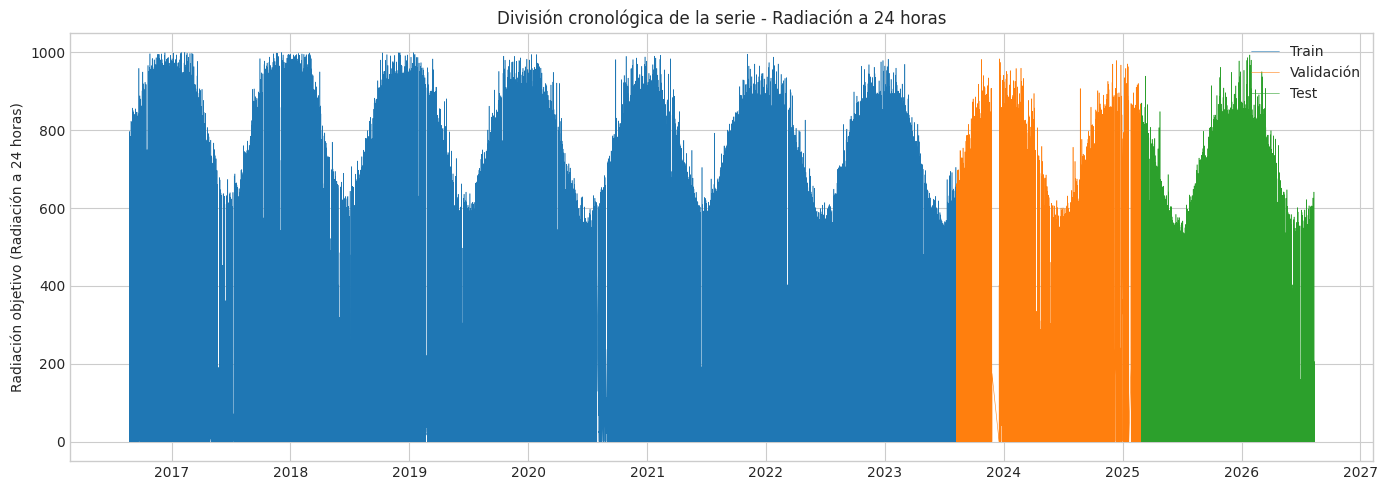

[24h] Filas diurnas -> train: 113689 | val (stop/blend): 12119 | val (ranking): 12119
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[24h] Objetivo: kt_objetivo | Cantidad de predictores: 54
AutoML progress: |
17:53:14.548: Project: radiacion_kt_24h
17:53:14.548: Cross-validation disabled by user: no fold column nor nfolds > 1.
17:53:14.548: Setting stopping tolerance adaptively based on the training frame: 0.002965792596794853
17:53:14.548: Build control seed: 42
17:53:14.549: training frame: Frame key: AutoML_1_20260927_175314_training_Key_Frame__upload_9ab34aedf768d0966943467fb9ad42f1.hex    cols: 57    rows: 113689  chunks: 18    size: 36813519  checksum: 7021010555559192660
17:53:14.549: validation frame: Frame key: Key_Frame__upload_883f81f61c7b9

/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,XGBoost_grid_1_AutoML_1_20260927_175314_model_4,0.276483,0.076443,0.215413,0.175166,0.076443
1,GBM_5_AutoML_1_20260927_175314,0.278488,0.077555,0.217956,0.176208,0.077555
2,GBM_2_AutoML_1_20260927_175314,0.279772,0.078272,0.218612,0.176834,0.078272
3,GBM_grid_1_AutoML_1_20260927_175314_model_1,0.280412,0.078631,0.219729,0.177301,0.078631
4,GBM_1_AutoML_1_20260927_175314,0.280478,0.078668,0.216387,0.177193,0.078668
5,GBM_3_AutoML_1_20260927_175314,0.280863,0.078884,0.220308,0.177409,0.078884
6,GBM_grid_1_AutoML_1_20260927_175314_model_3,0.282376,0.079736,0.221911,0.178434,0.079736
7,DRF_1_AutoML_1_20260927_175314,0.282709,0.079925,0.220686,0.178479,0.079925
8,GBM_4_AutoML_1_20260927_175314,0.283023,0.080102,0.219413,0.178717,0.080102
9,XRT_1_AutoML_1_20260927_175314,0.283381,0.080305,0.221208,0.179048,0.080305


[24h] Modelo ganador: XGBoost_grid_1_AutoML_1_20260927_175314_model_4
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%


/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


[24h] Métricas en test (modelo vs. referencias):


,MAE,RMSE,R2,MAPE_sin_ceros_pct,MAE_diurno,RMSE_diurno,MAE_max_diario,sesgo_max_diario,MAE_top10pct,sesgo_top10pct
H2O_AutoML_kt,50.970,102.913,0.832,119.140,112.200,152.312,121.289,-77.482,142.067,-140.971
persistencia,58.654,141.565,0.683,116.067,130.252,210.990,94.217,-11.172,146.484,-131.166
climatologia,59.642,109.121,0.811,144.012,130.657,160.349,166.463,-124.043,195.900,-195.900


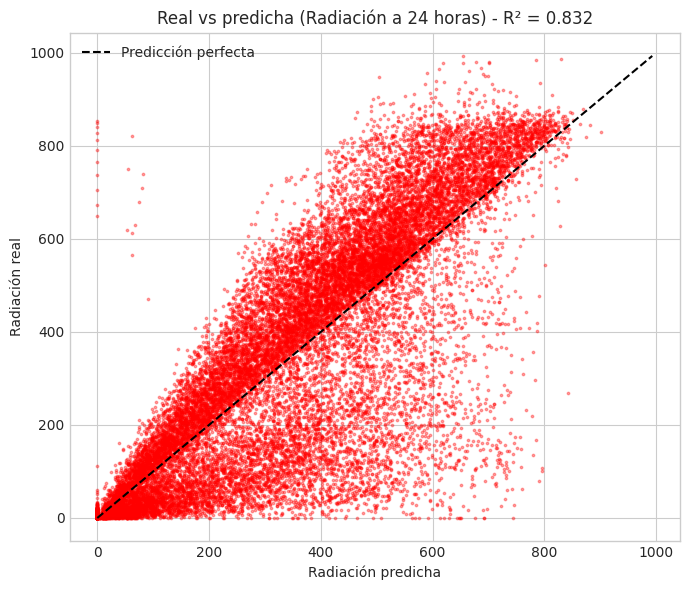

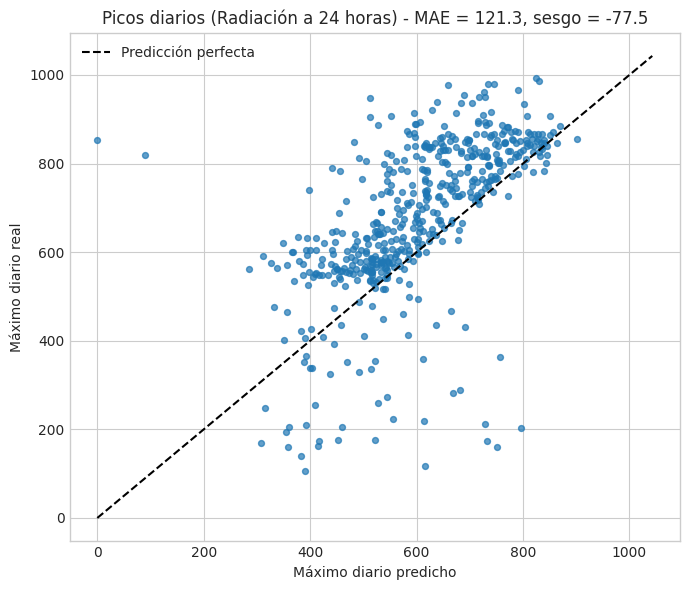

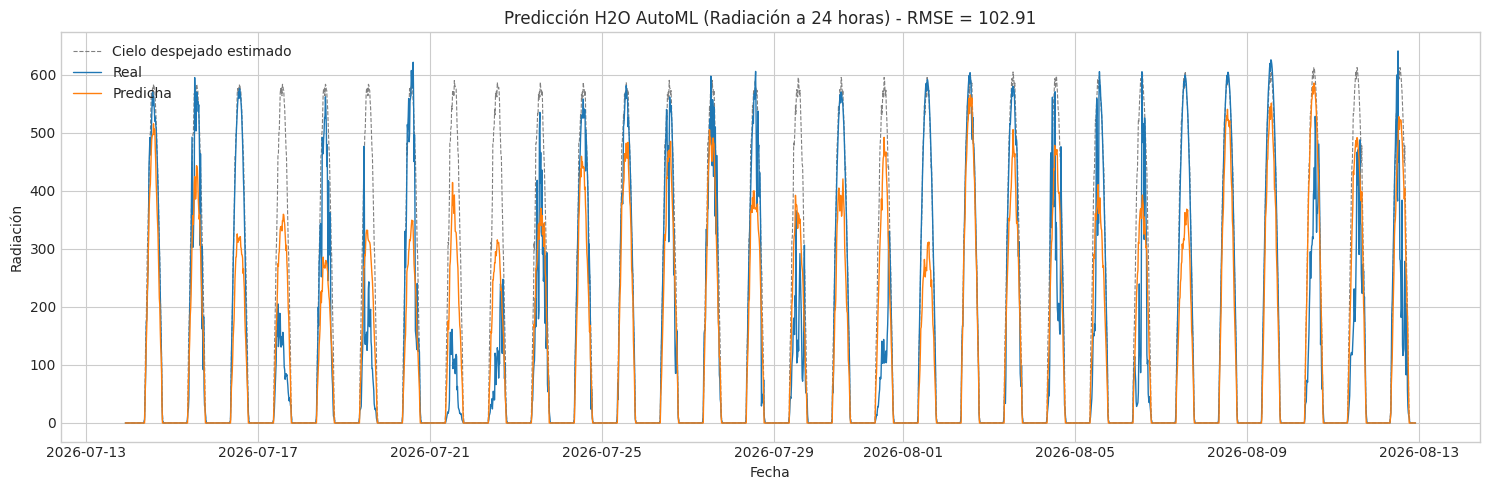

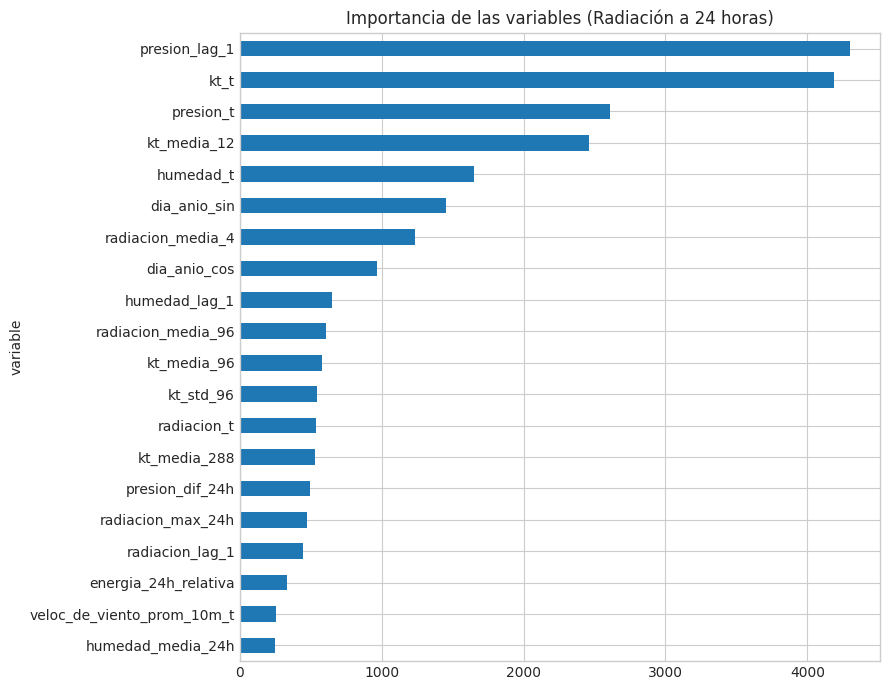

[24h] Modelo guardado en: /home/csosach/tp2/automl/resultados_h2o_radiacion_v2/24h/modelos/XGBoost_grid_1_AutoML_1_20260927_175314_model_4


In [17]:
resultado_24h = entrenar_evaluar_horizonte(96, '24h', 'Radiación a 24 horas')

## 14. Ejecución — pronóstico a 1 semana

672 pasos de 15 minutos hacia adelante.

=== Horizonte: Radiación a 1 semana (672 pasos de 15 min) ===
[7d] Filas utilizables: 333535
[7d] Entrenamiento: (233474, 57) 2016-08-24 01:00:00 2023-08-01 17:15:00
[7d] Validación: (50030, 57) 2023-08-01 17:30:00 2025-02-23 14:45:00
[7d] Prueba: (50031, 57) 2025-02-23 15:00:00 2026-08-05 22:15:00


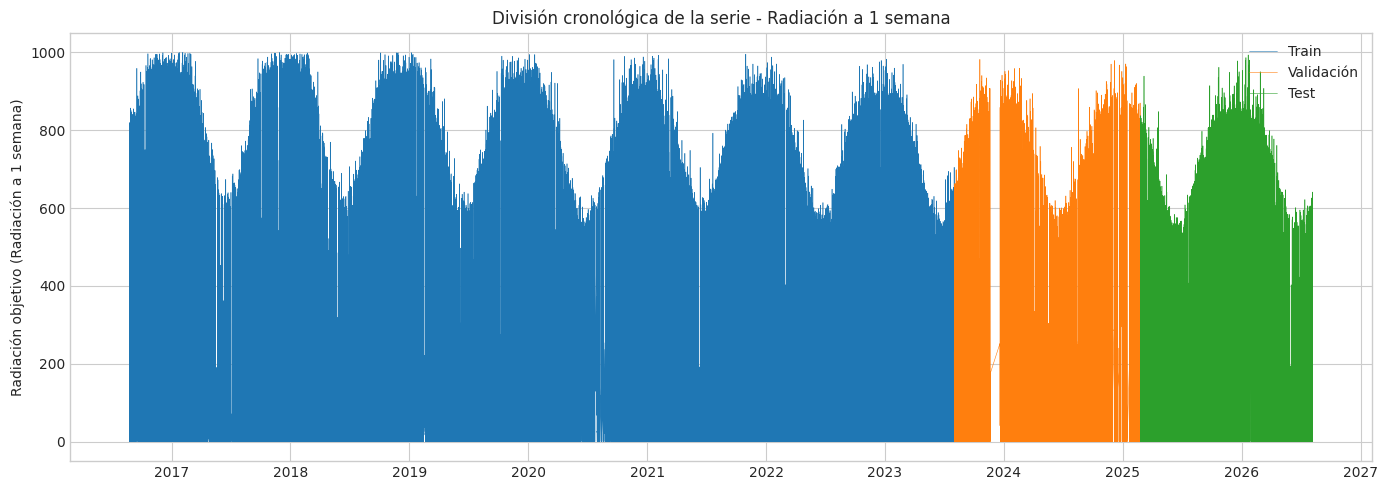

[7d] Filas diurnas -> train: 113435 | val (stop/blend): 12029 | val (ranking): 12030
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[7d] Objetivo: kt_objetivo | Cantidad de predictores: 54
AutoML progress: |
17:57:42.33: Project: radiacion_kt_7d
17:57:42.33: Cross-validation disabled by user: no fold column nor nfolds > 1.
17:57:42.33: Setting stopping tolerance adaptively based on the training frame: 0.002969111193759805
17:57:42.33: Build control seed: 42
17:57:42.33: training frame: Frame key: AutoML_2_20260927_175742_training_Key_Frame__upload_ad130af71e246cb536ee76dfb49b4f4a.hex    cols: 57    rows: 113435  chunks: 18    size: 36731851  checksum: -5045667736461947772
17:57:42.33: validation frame: Frame key: Key_Frame__upload_8a6ea583a71c6ffbd1350

/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,GLM_1_AutoML_2_20260927_175742,0.294820,0.086919,0.232047,0.187150,0.086919
1,GBM_2_AutoML_2_20260927_175742,0.295080,0.087072,0.234124,0.186814,0.087072
2,GBM_grid_1_AutoML_2_20260927_175742_model_1,0.296987,0.088201,0.237287,0.187960,0.088201
3,DRF_1_AutoML_2_20260927_175742,0.298162,0.088901,0.236374,0.188122,0.088901
4,GBM_5_AutoML_2_20260927_175742,0.298544,0.089129,0.240079,0.188587,0.089129
5,GBM_4_AutoML_2_20260927_175742,0.299004,0.089403,0.235960,0.188764,0.089403
6,XRT_1_AutoML_2_20260927_175742,0.300476,0.090286,0.238273,0.189334,0.090286
7,GBM_3_AutoML_2_20260927_175742,0.300694,0.090417,0.237836,0.189847,0.090417
8,GBM_grid_1_AutoML_2_20260927_175742_model_3,0.301263,0.090759,0.235400,0.190055,0.090759
9,GBM_1_AutoML_2_20260927_175742,0.302837,0.091711,0.237779,0.190466,0.091711


[7d] Modelo ganador: GLM_1_AutoML_2_20260927_175742
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


[7d] Métricas en test (modelo vs. referencias):


,MAE,RMSE,R2,MAPE_sin_ceros_pct,MAE_diurno,RMSE_diurno,MAE_max_diario,sesgo_max_diario,MAE_top10pct,sesgo_top10pct
H2O_AutoML_kt,54.662,107.563,0.817,150.716,119.035,157.472,121.020,-65.829,134.174,-133.852
persistencia,68.789,155.139,0.618,145.465,152.021,230.440,109.666,-5.324,167.063,-150.620
climatologia,60.357,110.298,0.807,157.615,131.949,162.171,165.937,-122.775,197.793,-197.793


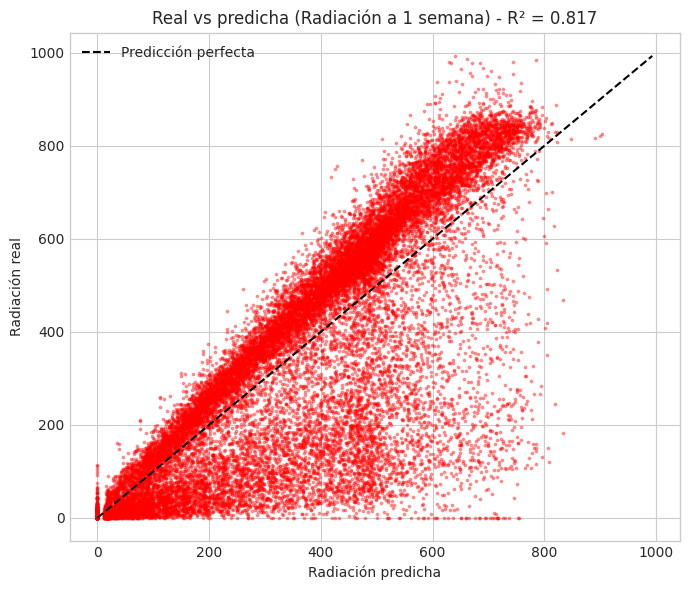

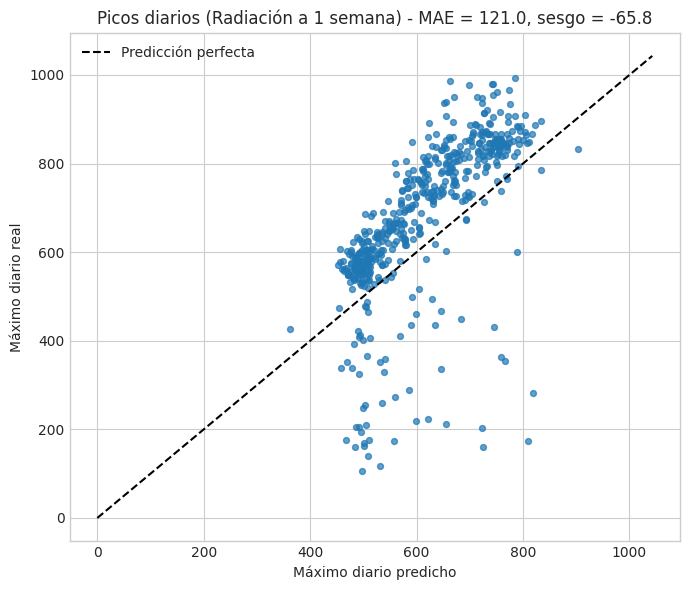

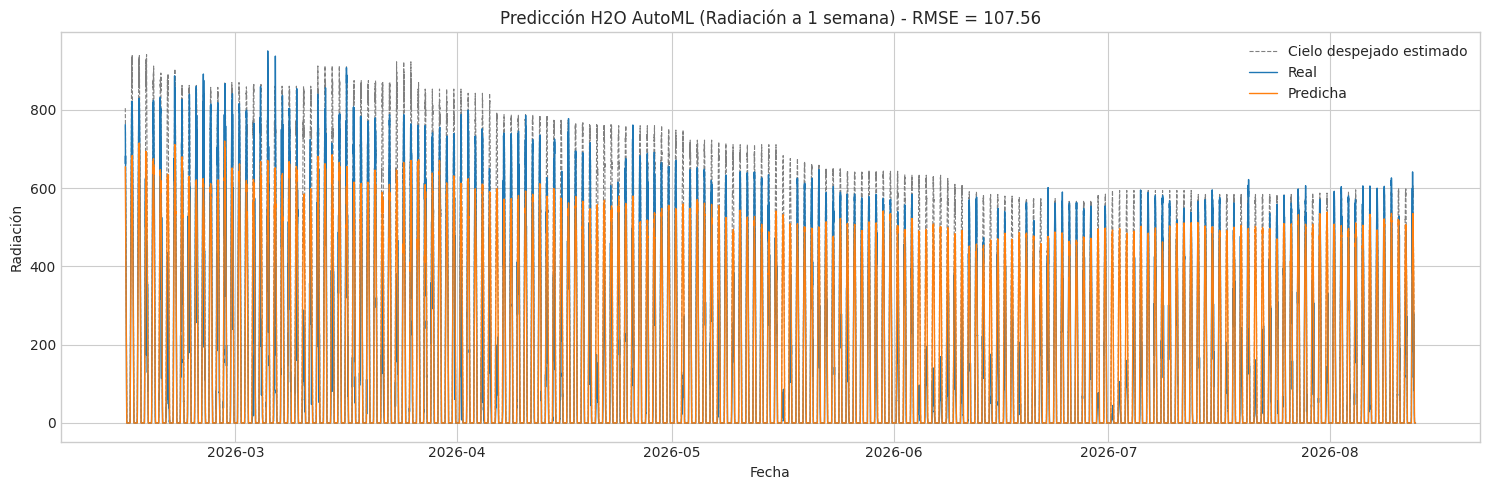

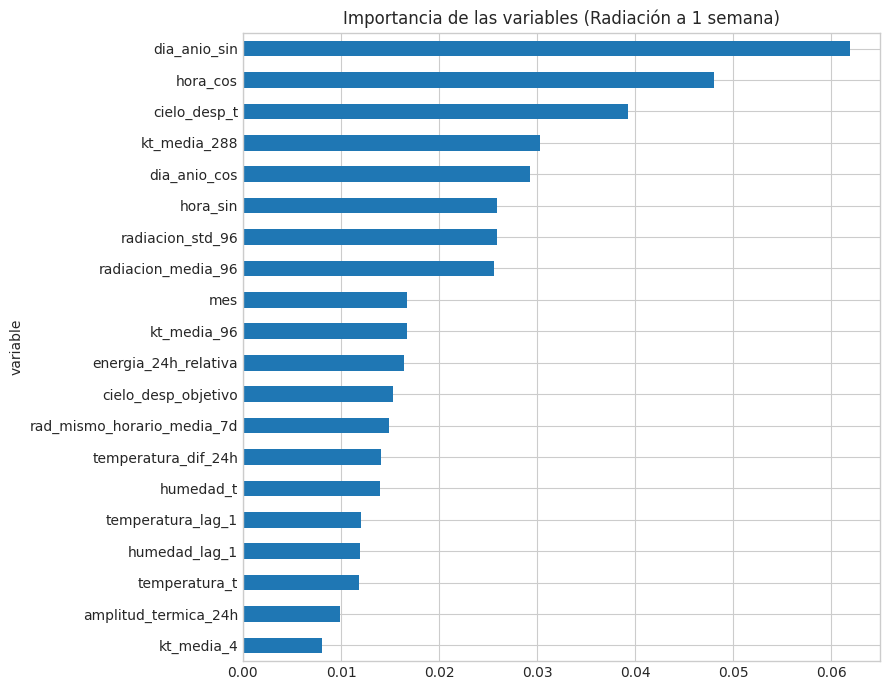

[7d] Modelo guardado en: /home/csosach/tp2/automl/resultados_h2o_radiacion_v2/7d/modelos/GLM_1_AutoML_2_20260927_175742


In [18]:
resultado_7d = entrenar_evaluar_horizonte(672, '7d', 'Radiación a 1 semana')

## 15. Comparación de métricas entre horizontes

In [19]:
tabla_comparativa = pd.DataFrame([resultado_24h, resultado_7d]).set_index('horizonte')
tabla_comparativa.to_csv(os.path.join(BASE_RESULTADOS, 'comparacion_horizontes.csv'))
tabla_comparativa

,pasos_15min,modelo_ganador,MAE,RMSE,R2,MAPE_sin_ceros_pct,MAE_diurno,RMSE_diurno,MAE_max_diario,sesgo_max_diario,MAE_top10pct,sesgo_top10pct
horizonte,,,,,,,,,,,,
24h,96,XGBoost_grid_1_AutoML_1_20260927_175314_model_4,50.969926,102.913193,0.832247,119.139751,112.199567,152.312175,121.288863,-77.481953,142.067449,-140.971318
7d,672,GLM_1_AutoML_2_20260927_175742,54.662045,107.563368,0.816501,150.716475,119.034929,157.472227,121.020331,-65.828920,134.173608,-133.851574


## 16. Cómo seguir mejorando los picos

- **Pronóstico de nubosidad como variable exógena.** Es la mejora más grande posible a 24 h: agregar la nubosidad o la radiación pronosticada por un modelo meteorológico para el día siguiente (por ejemplo, datos históricos de pronóstico de Open-Meteo, GFS o ECMWF para la ubicación de la estación). Sin esa información, el modelo sólo puede inferir el tiempo de mañana a partir de la presión, la humedad y lo ocurrido hoy.
- **Cielo despejado teórico.** Si se conocen la latitud y longitud de la estación, se puede reemplazar la envolvente empírica por un modelo físico (por ejemplo, `pvlib`), que no depende de que haya habido días despejados en las dos semanas previas.
- **Más tiempo de AutoML** (`TIEMPO_MAX_SEGUNDOS`, `MAX_MODELOS`) una vez que el flujo funcione.
- **Horizonte de 1 semana:** a 7 días la nubosidad es prácticamente impredecible con estos datos; es esperable que el modelo se acerque a la climatología. Si le gana a la climatología, ya es un buen resultado.

## 17. Cierre de H2O
Ejecutar esta celda cuando ya no se utilizará el clúster H2O.

In [ ]:
h2o.cluster().shutdown(prompt=False)